Epoch [10/50], Loss: 0.000123
Epoch [20/50], Loss: 0.000124
Epoch [30/50], Loss: 0.000123
Epoch [40/50], Loss: 0.000119
Epoch [50/50], Loss: 0.000121


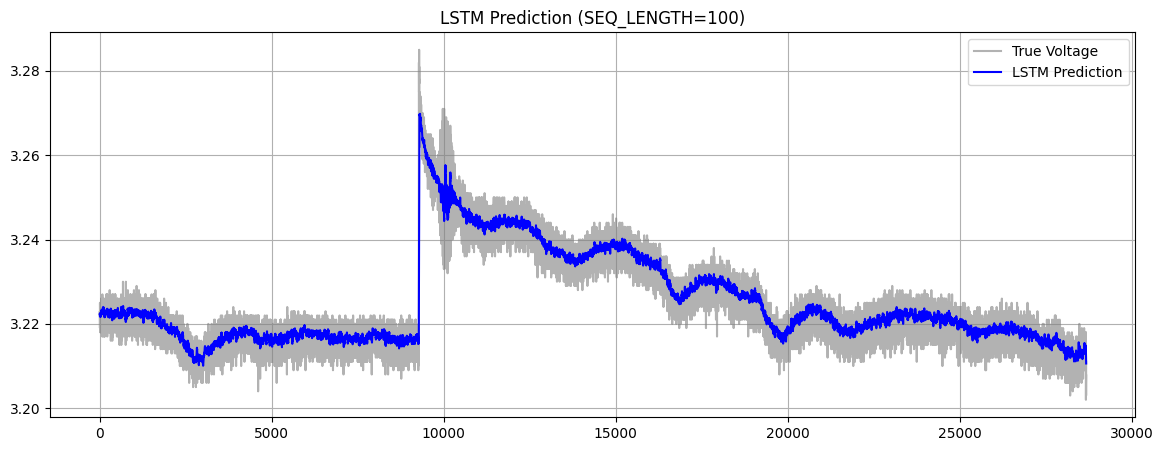

🔥 强化版 LSTM 测试集 RMSE: 0.003179 V


In [6]:
#加强版LSTM和盲测版本
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error

# ==========================================
# 第一部分：读数据与防泄漏归一化
# ==========================================
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv'
df = pd.read_csv(file_path)

# 【关键】我们这次不仅拿电压，还拿时间！让模型知道现在走到了寿命的哪个阶段。
# data 现在的形状是：[65529行, 2列]，第0列是时间，第1列是电压
data = df[['Time (h)', 'Utot (V)']].values

# 划分训练集（前 80%）和测试集（后 20%）
train_size = int(len(data) * 0.8)
train_data = data[:train_size]  # 前面的数据当教材
test_data = data[train_size:]   # 后面的数据当考卷

# 归一化（把大数字压缩到 0~1 之间）
scaler = MinMaxScaler(feature_range=(0, 1))
# 【防作弊机制】scaler 只让训练集去 fit（找最大值和最小值），不能看测试集！
train_scaled = scaler.fit_transform(train_data)
# 用训练集的标准去压缩测试集
test_scaled = scaler.transform(test_data)

#为什么 [[3.2], [3.1], [3.3]] 是 [3, 1] 不是 [1, 3]？
#在数学和编程里，行代表样本（数量）（行数），列代表特征（种类）（列数）。
#这里有 3 个独立的预测结果（3 行），每个结果只有 1 个电压值（1 列），所以是 3 行 1 列，即 [3, 1]。

# ==========================================
# 第二部分：滑动窗口切分数据 (重点，看不懂对照上面的解释)
# ==========================================
def create_sequences(data, seq_length):#Sequence Length（序列长度）它代表你每次给模型看多长的“历史”
    #def：代表“我现在要开始写说明书了”。create_sequences：是这台榨汁机的名字，(data, seq_length)：是这台榨汁机要求的原材料（也就是你要丢进去的水果）。在这里，你需要给它一块完整的数据，和你要切分的长度。下面缩进的那些代码（xs = [] 等等）：就是机器内部的齿轮怎么转、刀片怎么切。
    #当你敲下这一行时：
    #X_lstm, y_lstm = create_sequences(data_scaled, SEQ_LENGTH)

    #这时候，你等于把 data_scaled（真实的果实）和 SEQ_LENGTH 塞进了这台名叫 create_sequences 的机器里。
    #机器开始运转
    #def create_sequences(data, seq_length)意思是：“一会儿我调用这个函数时，会传两个值进来，第一个交data，第二个值我就叫它 seq_length”。
    xs = [] # 用来装历史的篮子
    ys = [] # 用来装未来答案的篮子
    # len(data) 是总行数。为了不越界，循环只能跑到 len - seq_length
    for i in range(len(data) - seq_length):
        # 切出一段历史：从第 i 行，切到第 i + seq_length 行
        # 形状是 (seq_length, 2)，包含了时间和电压
        x = data[i : i + seq_length]#[i : i + seq_length]不包含i + seq_length，切分默认左闭右开。
        #你的担心非常专业（怕预测出无法验证的边界点）。但不需要减 1。
        #Python 的 range(n) 产生的是 0 到 n-1


        # 【关键点】切出未来：从 i + seq_length 这个位置，只取第 1 列（电压），第0列是时间
        # 形状是 (1,)，就是一个数
        y = data[i + seq_length, 1]#data[行,列]没错！！！i + seq_length是数字，就是代表行。
        #跑一python默认第一列是0列，第二列是1列
        xs.append(x) # 把历史塞进篮子
        ys.append(y) # 把答案塞进篮子
    return np.array(xs), np.array(ys)

# 用过去 100 个点预测下一个点
SEQ_LENGTH = 100
X_train_lstm, y_train_lstm = create_sequences(train_scaled, SEQ_LENGTH)
X_test_lstm, y_test_lstm = create_sequences(test_scaled, SEQ_LENGTH)

# 转成 PyTorch 认的 Tensor
# 注意：X_train_lstm 的形状是 [样本数, 100, 2]，因为包了时间和电压两个特征
X_train_tensor = torch.FloatTensor(X_train_lstm)

# 【重点】y_train_lstm 是一维数组 [样本数]，通过 unsqueeze(1) 变成二维 [样本数, 1]
# 如果不加，PyTorch 算误差时会报形状不匹配的错
y_train_tensor = torch.FloatTensor(y_train_lstm).unsqueeze(1)

X_test_tensor = torch.FloatTensor(X_test_lstm)
y_test_tensor = torch.FloatTensor(y_test_lstm).unsqueeze(1)


# ==========================================
# 第三部分：搭建神经网络结构
# ==========================================
class VoltageLSTM(nn.Module):
    # 这就是“配置单”。input_size=2 因为有两个特征(时间+电压)
    def __init__(self, input_size=2, hidden_size=48, num_layers=2, output_size=1):#（所有程序员都默认神经网络用self）
        super(VoltageLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        # LSTM 层：64个神经元，2层深，batch_first=True 表示第0维是批次大小
        self.fc = nn.Linear(hidden_size, output_size)
        # .fc全连接层：把 LSTM 的 64 维输出，压缩成 1 维的最终电压预测值，全连接层负责“算”
        #LSTM 这个“大胃王”吃了 50 个历史点，最后吐出来一个 48 维的向量（hidden_size=48）。这 48 个数字包含了复杂的趋势、波动、记忆。
        #可是评委只要一个数字（预测电压 3.21V）。怎么把这 48 个数字变成一个数字？
        #全连接层就是 y = w1*x1 + w2*x2 + ... + w48*x48 + b。
        #它给这 48 个特征各分配一个权重（w），加在一起，最后得出预测电压。
        #就好比 LSTM 是做了 48 页的分析报告，全连接层是局长，局长扫了一眼报告，写了一句话总结：“结论：电压是 3.21V”。


    def forward(self, x):
        # 把 x 塞进 LSTM
        out, _ = self.lstm(x)
        # out[:, -1, :] 意思是：取所有样本的【最后一个时间步】的输出
        out = self.fc(out[:, -1, :])
        return out

model = VoltageLSTM()
# MSELoss 就是均方误差，专门算预测值和真实值差多少
criterion = nn.MSELoss()
# Adam 是优化器，负责根据误差去调整模型里面的旋钮
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

from torch.utils.data import DataLoader, TensorDataset

# 1. 把 X 和 Y 打包成 PyTorch 的数据集
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# 2. 创建 DataLoader（自动打乱、自动分批）
BATCH_SIZE = 512 # 一次只喂 512 个样本，保护内存
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. 全新的训练循环
epochs = 50
loss_history = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    # 注意：这里变成从 train_loader 里一批一批拿数据了
    for batch_X, batch_y in train_loader:
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f}')

# ==========================================
# 第四部分：训练循环
# ==========================================
#epochs = 15 # 把 100 个点的历史学 50 遍
#loss_history = []
#torch.set_num_threads(4)

#for epoch in range(epochs):
#    model.train() # 标记现在是训练模式
#    outputs = model(X_train_tensor) # 前向传播，让模型瞎猜
#    loss = criterion(outputs, y_train_tensor) # 算瞎猜的误差

#    optimizer.zero_grad() # 清空上一轮的旧账
#    loss.backward()       # 反向传播，找出哪个旋钮调错了
#    optimizer.step()      # 拧旋钮，更新参数

#    loss_history.append(loss.item())
#    if (epoch+1) % 10 == 0:
#        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.6f}')

# ==========================================
# 第五部分：测试与还原
# ==========================================
model.eval() # 标记现在是考试模式
with torch.no_grad(): # 考试不需要更新旋钮，关掉以节省内存
    predictions = model(X_test_tensor)

# 因为之前把数据压缩成了 0~1，现在要反归一化，变回真实的 3.x 伏特
# 这里稍微有点绕：为了利用 scikit-learn 的 inverse_transform，我们需要伪造一个两列的假数据
dummy = np.zeros((len(predictions), 2))
dummy[:, 1] = predictions.numpy().flatten()
predictions_real = scaler.inverse_transform(dummy)[:, 1]

dummy_y = np.zeros((len(y_test_tensor), 2))
dummy_y[:, 1] = y_test_tensor.numpy().flatten()
y_test_real = scaler.inverse_transform(dummy_y)[:, 1]

# ==========================================
# 第六部分：出图
# ==========================================
plt.figure(figsize=(14, 5))
plt.plot(y_test_real, label='True Voltage', color='gray', alpha=0.6)
plt.plot(predictions_real, label='LSTM Prediction', color='blue')
plt.title(f'LSTM Prediction (SEQ_LENGTH={SEQ_LENGTH})')
plt.legend()
plt.grid(True)
plt.show()

rmse = math.sqrt(mean_squared_error(y_test_real, predictions_real))
print(f"🔥 强化版 LSTM 测试集 RMSE: {rmse:.6f} V")

In [2]:
print("显卡可用吗？", torch.cuda.is_available())

显卡可用吗？ False


In [1]:
##以下是盲测版本
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 读取【纯训练集】 =================
# 这个文件里只有 0~920h 的数据，绝对没有未来！
file_path = r'C:\Users\YOGA\Desktop\测试集.csv'
df_train_only = pd.read_csv(file_path)

# 提取时间和电压
data_train = df_train_only[['Time (h)', 'Utot (V)']].values

# 归一化：这里可以直接 fit_transform 了，因为数据里绝对没有未来
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(data_train)

# ================= 2. 训练模型 =================
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i : i + seq_length])
        ys.append(data[i + seq_length, 1])
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 100
X_train_lstm, y_train_lstm = create_sequences(train_scaled, SEQ_LENGTH)
X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm).unsqueeze(1)

class VoltageLSTM(nn.Module):
    def __init__(self, input_size=2, hidden_size=32, num_layers=1, output_size=1):
        super(VoltageLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

model = VoltageLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=512, shuffle=True)

print("开始训练（仅用 0~920h 数据）...")
epochs = 15
for epoch in range(epochs):
    model.train()
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
print("训练完成！")

# ================= 3. 纯盲测外推 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)

    # 【硬性规定】让它往后预测 13000 步（大致等于剩下的 20% 长度）
    steps_to_predict = 14000

    predicted_voltages = []
    current_input = seed

    time_diff = data_train[1, 0] - data_train[0, 0]
    current_time = data_train[-1, 0]

    print(f"开始盲测，强迫它凭空推演 {steps_to_predict} 步...")
    for _ in range(steps_to_predict):
        pred_y = model(current_input)
        predicted_voltages.append(pred_y.item())

        current_time += time_diff
        next_time_scaled = scaler.transform([[current_time, 0]])[0, 0]
        next_step = torch.FloatTensor([[[next_time_scaled, pred_y.item()]]])

        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# 把预测值反归一化成真实电压
dummy = np.zeros((len(predicted_voltages), 2))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

# ================= 4. 读取真实未来数据（仅用于画图对比） =================
# 为了让你亲眼看到它错得有多离谱，我们才去读完整数据
df_full = pd.read_csv(r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv')
split_idx = len(df_train_only) # 训练集的长度
true_future = df_full['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

from sklearn.metrics import mean_squared_error
import math

# 确保长度对齐（因为可能有一些边角料没切干净）
min_len = min(len(predictions_real), len(true_future))
rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))

print(f"🚨 纯盲测（13000步）的 RMSE: {rmse_blind:.6f} V")
print("（你会发现这个值巨大，因为直线根本跟不上真实的断崖下跌。）")

# ================= 5. 画图 =================
plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='True Voltage (真实后半段，模型没见过的)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='LSTM Pure Prediction (凭空盲猜)', color='blue')
plt.title('Pure Blind Extrapolation (No Future Data Leaked)')
plt.xlabel('Time Steps (After 920h)')
plt.ylabel('Utot (V)')
plt.legend()
plt.grid(True)
plt.show()